# Frente B: de la señal limpia a la tabla de descriptores (etapas 6 a 9)

Este notebook cuenta el recorrido completo del Frente B y arma la tabla que recibe el
Frente C. Cada técnica tiene su propio capítulo, con el detalle de qué se le hace a la
señal y por qué.

| Capítulo | Notebook | Señal | Qué mide | Estadio que delata |
|---|---|---|---|---|
| 1. Espectro | `02a_frente_B_espectro` | Los 4 EEG | Potencia de cada ritmo y pendiente del espectro | Todos, sobre todo W y N3 |
| 2. Husos | `02b_frente_B_husos` | EEG central (C4) | Ráfagas de 11 a 16 Hz | N2 |
| 3. Ondas lentas y Woody | `02c_frente_B_ondas_lentas_woody` | EEG frontal (F4) | Ondas grandes de menos de 4 Hz y su forma | N3 |
| 4. CSP | `02d_frente_B_csp` | Los 4 EEG combinados | Diferencias entre zonas del cerebro | N1 frente a REM |
| 5. EOG y EMG | `02e_frente_B_eog_emg` | EOG y EMG de mentón | Movimientos oculares y tono muscular | REM y W |

## La historia en una figura

```
                         Frente A                 Frente B                          Frente C
Registro crudo ──► RegistroPreprocesado ──► TablaDescriptores ──────────────► hipnograma
                   señales limpias, en µV     una fila por época de 30 s
                                              ├─ espectro.*     (56)   cap. 1
                                              ├─ husos.*        (2)    cap. 2
                                              ├─ ondas.*        (3)    cap. 3
                                              ├─ perifericos.*  (2)    cap. 5
                                              ├─ hrv.*          (lo calcula el Frente A)
                                              └─ covarianzas    (4×4)  cap. 4, para CSP
```

El Frente B no clasifica: **mide**. Toma cada época de 30 s y la resume en unos 60
números que describen lo que el manual AASM mira para decidir el estadio, como los
ritmos del EEG, los husos, las ondas lentas, los movimientos oculares y el tono
muscular. La decisión la toma el Frente C con esos números.

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base, SN122 (un
paciente de entrenamiento), y los números del texto son de ese paciente. Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian.

Las señales llegan **preprocesadas** por el Frente A (`pipeline.preprocesar`): filtradas
entre 0,2 y 45 Hz con notch en 50 Hz, sin artefacto ocular (Wiener con compuerta) y sin
artefacto cardíaco. El EMG va con un pasa-altos de 10 Hz. La señal cruda queda en
`crudo` para comparar.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    # La señal cruda se guarda para comparar; los descriptores usan la preprocesada.
    # SN122 es el paciente de ejemplo de los textos; si no está, se usa el primero.
    disponibles = ids_disponibles()
    crudo = cargar_registro("SN122" if "SN122" in disponibles else disponibles[0])
    prep = preprocesar(crudo, Config().preprocesamiento)
else:
    prep = preprocesado_sintetico(minutos=120)
    crudo = prep.registro

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. La señal que entra

Una época de 30 s es la unidad de todo el trabajo: los técnicos le asignan un estadio,
y el Frente B le calcula sus descriptores. Este es el hipnograma de los técnicos para
el registro, la secuencia de estadios de toda la noche.

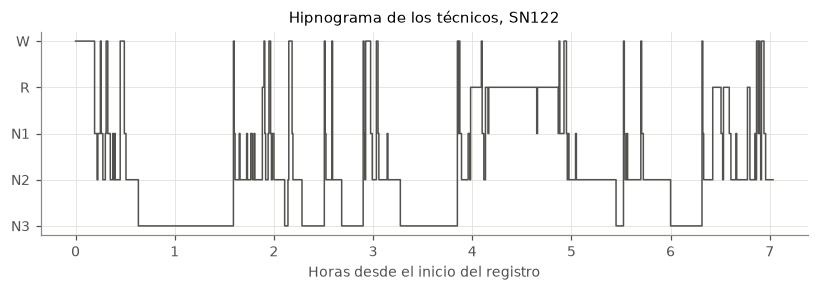

In [4]:
orden = ["N3", "N2", "N1", "R", "W"]
nivel = np.array([orden.index(NOMBRES_ESTADIOS[e]) if e >= 0 else np.nan for e in estadios_tecnicos])
horas = np.arange(registro.n_epocas) * 30 / 3600

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.step(horas, nivel, where="post", color=TINTA, lw=1)
ax.set(yticks=range(len(orden)), yticklabels=orden, xlabel="Horas desde el inicio del registro",
       title=f"Hipnograma de los técnicos, {registro.id}")
guardar(fig, "b_hipnograma_tecnicos")

Y esto es lo que el Frente B recibe de una época: las ocho señales de la
polisomnografía durante 30 s. Se muestra una época de N2.

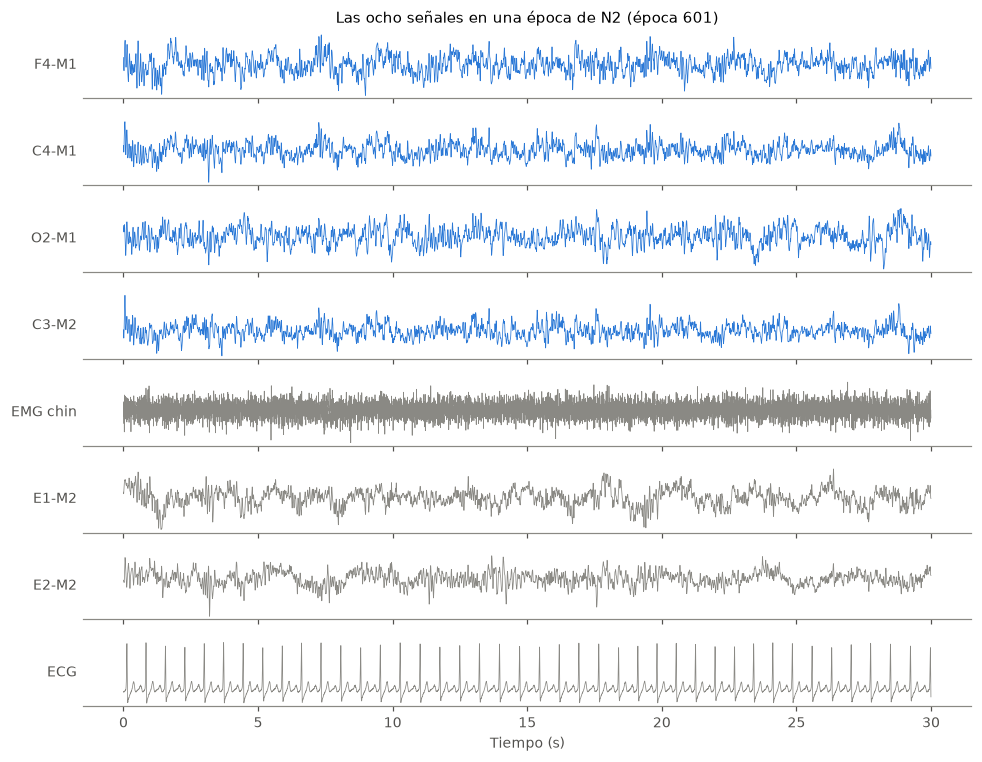

In [5]:
from estadios.comun.constantes import CANALES, N2

epocas_n2 = np.flatnonzero(estadios_tecnicos == N2)
j = epocas_n2[len(epocas_n2) // 2]
n_epoca = int(30 * fs)
tramo = slice(j * n_epoca, (j + 1) * n_epoca)
t = np.arange(n_epoca) / fs

fig, axs = plt.subplots(len(CANALES), 1, figsize=(9, 7), sharex=True)
for ax, canal in zip(axs, CANALES):
    ax.plot(t, registro.senales[canal][tramo], color=AZUL if canal.startswith("EEG") else GRIS, lw=0.5)
    ax.set_ylabel(canal.replace("EEG ", "").replace("EOG ", ""), rotation=0, ha="right", va="center")
    ax.grid(False)
    ax.tick_params(labelleft=False, left=False)
    ax.spines["left"].set_visible(False)
axs[-1].set(xlabel="Tiempo (s)")
axs[0].set_title(f"Las ocho señales en una época de N2 (época {j})")
fig.tight_layout()
guardar(fig, "b_epoca_ocho_senales")

Los cuatro EEG (azul) son los que más información aportan, y cada capítulo los mira de
una manera distinta. El EOG y el EMG se usan sobre todo para REM. El ECG lo usa el
Frente A para detectar latidos y calcular la HRV.

## 2. La tabla de descriptores

`ensamblado.describir_registro()` llama a cada capítulo y junta sus resultados en una
`TablaDescriptores`: una fila por época, una columna por descriptor, más las
covarianzas para CSP. Acá se arma la tabla grupo por grupo para ver qué aporta cada
uno. Los cuatro primeros son del Frente B. El último, `hrv`, lo calcula el Frente A con
los latidos de Pan-Tompkins: el logaritmo de la potencia HF y del cociente LF/HF, en una
ventana de 5 minutos centrada en cada época.

In [6]:
from estadios.descriptores import espectro, hrv, husos, ondas_lentas, perifericos

grupos = {
    "espectro": espectro.descriptores_espectrales(prep, cfg),
    "husos": husos.descriptores_husos(prep, cfg),
    "ondas": ondas_lentas.descriptores_ondas_lentas(prep, cfg),
    "perifericos": perifericos.descriptores_perifericos(prep, cfg),
    "hrv (Frente A)": hrv.descriptores_hrv(prep, cfg),
}
matriz = np.hstack([m for m, _ in grupos.values()])
nombres = [n for _, ns in grupos.values() for n in ns]
print(f"{matriz.shape[0]} épocas × {matriz.shape[1]} descriptores")
for grupo, (_, ns) in grupos.items():
    print(f"  {grupo:12s} {len(ns):3d}")

845 épocas × 65 descriptores
  espectro      56
  husos          2
  ondas          3
  perifericos    2
  hrv (Frente A)   2


## 3. Estandarizar dentro de cada noche

Los descriptores tienen escalas muy distintas: una potencia relativa va de 0 a 1, una
cantidad de husos de 0 a 10 y una pendiente es negativa. Además, el mismo descriptor
cambia de nivel de un paciente a otro por cosas que no tienen que ver con el sueño, como
la impedancia de los electrodos.

Por eso `estandarizar_por_registro()` lleva cada descriptor a media 0 y desvío 1
**dentro de cada noche**. Después de eso, un valor de +2 significa "dos desvíos por
encima de lo habitual para este paciente", sin importar la unidad ni el paciente.

La tabla muestra el promedio estandarizado de algunos descriptores en cada estadio: es
la "huella" que deja cada estadio en lo que mide el Frente B.

In [7]:
import pandas as pd
from estadios.descriptores.ensamblado import estandarizar_por_registro

z = estandarizar_por_registro(matriz)
elegidos = {
    "espectro.c4_delta_rel": "δ relativa (C4)",
    "espectro.o2_alfa_rel": "α relativa (O2)",
    "espectro.c4_pendiente": "Pendiente (C4)",
    "husos.cantidad": "Husos por época",
    "ondas.cantidad": "Ondas lentas por época",
    "perifericos.energia_eog": "Energía del EOG",
    "perifericos.amplitud_emg": "Amplitud del EMG",
    "hrv.lf_hf": "LF/HF (HRV, Frente A)",
}
huella = pd.DataFrame(
    {nombre: [z[estadios_tecnicos == e, nombres.index(clave)].mean() for clave in elegidos]
     for e, nombre in enumerate(NOMBRES_ESTADIOS) if (estadios_tecnicos == e).any()},
    index=list(elegidos.values()),
).round(2)
huella

,W,N1,N2,N3,R
δ relativa (C4),-1.37,-0.98,-0.42,1.03,-0.11
α relativa (O2),1.68,0.58,0.17,-0.78,0.20
Pendiente (C4),2.12,1.13,-0.17,-0.65,0.18
Husos por época,0.61,-0.25,0.45,-0.27,-0.67
Ondas lentas por época,-0.33,-0.57,-0.47,1.00,-0.70
Energía del EOG,0.62,-0.43,-0.69,0.21,1.13
Amplitud del EMG,1.64,0.76,-0.15,0.06,-1.07
"LF/HF (HRV, Frente A)",0.22,0.17,0.11,-0.58,0.89


Cada estadio tiene su combinación. W tiene la α, el EMG y la pendiente más altos (un
espectro más plano). N3 tiene la δ y las ondas lentas un desvío por encima de lo
habitual. REM tiene el EOG y el cociente LF/HF de la HRV más altos y el EMG más bajo de
todos, que son la firma de los movimientos oculares y de la atonía. N1 queda entre W y N2
en casi todo, y por eso es el estadio más difícil, porque se reconoce más por lo que no
tiene que por lo que tiene.

La fila de husos tiene una sorpresa. W queda más alto (+0,61) que N2 (+0,45), lo mismo
que se vio en el capítulo 2. Las ráfagas de la vigilia activa pasan el detector.

Esa tabla es, en resumen, lo que el Frente B le entrega al Frente C para decidir.

## 4. La misma huella en todos los pacientes

Un solo paciente puede engañar. `scripts/calcular_descriptores.py` deja la tabla de
cada registro en la caché (`data/descriptores/`). Acá se leen las de los pacientes de
**entrenamiento**, los mismos que usó el Frente A para elegir sus parámetros (los de
prueba quedan para las hipótesis). Cada tabla se recorta al período entre luces
apagadas y encendidas, igual que en el Frente C, y se calcula la huella de **cada
paciente** por separado. Cada caja de la figura
reúne a todos los pacientes: si es angosta y está lejos de cero, el descriptor separa
ese estadio de forma consistente y no solo en una noche.

Tablas de entrenamiento en la caché: 56


estadio,W,N1,N2,N3,R
δ relativa (C4),-0.62,-0.44,0.04,0.97,-0.26
α relativa (O2),0.75,0.22,-0.11,-0.74,0.07
Pendiente (C4),1.53,0.79,-0.33,-1.00,0.19
Husos por época,0.31,-0.25,0.19,-0.17,-0.51
Ondas lentas por época,0.25,-0.27,-0.18,0.66,-0.50
Energía del EOG,0.92,0.21,-0.56,-0.23,0.46
Amplitud del EMG,1.35,0.45,-0.17,-0.48,-0.67
"LF/HF (HRV, Frente A)",0.14,0.22,-0.01,-0.60,0.50


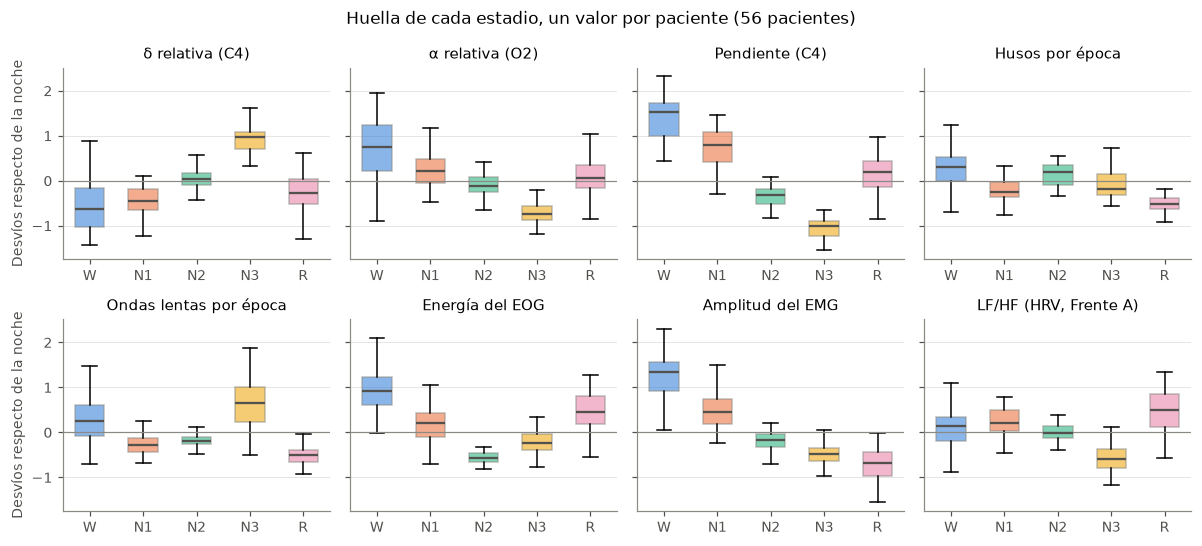

In [8]:
from estadios.comun.contratos import TablaDescriptores
from estadios.evaluacion.periodo import recortar_a_periodo_de_sueno
from estadios.pipeline import DIR_CACHE

carpeta = DIR_CACHE / Config().huella_descriptores()
from estadios.datos.particion import particion_por_paciente

rutas = sorted(carpeta.glob("SN*.npz"))
if rutas:
    entrenamiento, _ = particion_por_paciente([r.stem for r in rutas])
    rutas = [r for r in rutas if r.stem in entrenamiento]
print(f"Tablas de entrenamiento en la caché: {len(rutas)}")

if rutas:
    filas = []
    for ruta in rutas:
        t = recortar_a_periodo_de_sueno(TablaDescriptores.cargar(ruta))
        zt = estandarizar_por_registro(t.matriz)
        for e, nombre in enumerate(NOMBRES_ESTADIOS):
            if (t.estadios == e).sum() >= 10:  # Al menos 5 minutos de ese estadio.
                fila = {"paciente": t.id, "estadio": nombre}
                fila.update({etq: zt[t.estadios == e, t.nombres.index(c)].mean() for c, etq in elegidos.items()})
                filas.append(fila)
    por_paciente = pd.DataFrame(filas)
    display(por_paciente.groupby("estadio", sort=False)[list(elegidos.values())].median().T.round(2))

    fig, axs = plt.subplots(2, 4, figsize=(11, 5), sharey=True)
    for ax, etq in zip(axs.flat, elegidos.values()):
        grupos_e = [por_paciente.loc[por_paciente.estadio == n, etq] for n in NOMBRES_ESTADIOS]
        cajas = ax.boxplot(grupos_e, tick_labels=NOMBRES_ESTADIOS, showfliers=False, patch_artist=True,
                           widths=0.55, medianprops={"color": TINTA, "linewidth": 1.5})
        for caja, n in zip(cajas["boxes"], NOMBRES_ESTADIOS):
            caja.set(facecolor=COLOR_ESTADIO[n], alpha=0.55, edgecolor=GRIS)
        ax.axhline(0, color=GRIS, lw=0.8)
        ax.set_title(etq)
        ax.grid(axis="x", visible=False)
    for ax in axs[:, 0]:
        ax.set_ylabel("Desvíos respecto de la noche")
    fig.suptitle(f"Huella de cada estadio, un valor por paciente ({por_paciente.paciente.nunique()} pacientes)")
    fig.tight_layout()
    guardar(fig, "b_huella_pacientes")
else:
    print("No hay caché: correr antes scripts/calcular_descriptores.py.")

La huella de SN122 se repite en los 56 pacientes. Las cajas de la pendiente no se tocan
entre W y N3: la pendiente es más empinada en N3 que en W en **los 56**. La δ es máxima
en N3 en 49 de 56 y el EMG es mínimo en REM en 43 de 56. El LF/HF del Frente A separa
bien N3 (−0,60) de REM (+0,50).

Dos descriptores no hacen lo que dice el manual. La caja de husos de W (+0,31) queda por
encima de la de N2 (+0,19), y W tiene más husos que N2 en 34 de los 56 pacientes. En
todos, las épocas de W con detecciones tienen el EMG más alto que las que no tienen
ninguna (mediana de 17 contra 7 µV), y en 55 de 56 tienen menos α. Con las ondas lentas
pasa lo mismo, aunque N3 sigue arriba (+0,66 contra +0,25 de W).

El EOG tampoco separa REM como se esperaba, porque W lo tiene todavía más alto (+0,92
contra +0,46). Esto no es un problema mientras la regla de REM se aplique después de la
de W, pero confirma que REM se reconoce por la combinación de EOG, EMG y LF/HF y no por
un solo descriptor.